# 01 · Problem framing and data understanding

**Scenario.** A wearable maker wants to recognise what a user is doing (walking, climbing stairs, sitting,
standing, laying) directly on a low-cost device. The model has to work for **people it has never seen**,
run on a weak CPU, fit in little memory and stay explainable. So the question is not only *which model is
most accurate*, but *which model gives the best trade-off*.

**Data.** [UCI HAR](https://doi.org/10.24432/C54S4K): 30 people wearing a smartphone on the waist, six
activities, 10,299 windows of 2.56 s, each described by 561 engineered accelerometer and gyroscope features.

This notebook loads the raw data (downloaded on first run) and checks its structure and quality.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from edgefit.data import load_har

X, y, groups, label_map = load_har()
activity = y.map(label_map)
print(f"Feature matrix: {X.shape} | subjects: {groups.nunique()} | missing values: {int(X.isna().sum().sum())}")
print(f"Feature range: [{X.min().min():.2f}, {X.max().max():.2f}]")

Feature matrix: (10299, 561) | subjects: 30 | missing values: 0
Feature range: [-1.00, 1.00]


## Class balance

In [2]:
freq = activity.value_counts().rename_axis("activity").reset_index(name="count")
freq["share"] = (freq["count"] / freq["count"].sum()).round(4)
freq

,activity,count,share
0,LAYING,1944,0.1888
1,STANDING,1906,0.1851
2,SITTING,1777,0.1725
3,WALKING,1722,0.1672
4,WALKING_UPSTAIRS,1544,0.1499
5,WALKING_DOWNSTAIRS,1406,0.1365


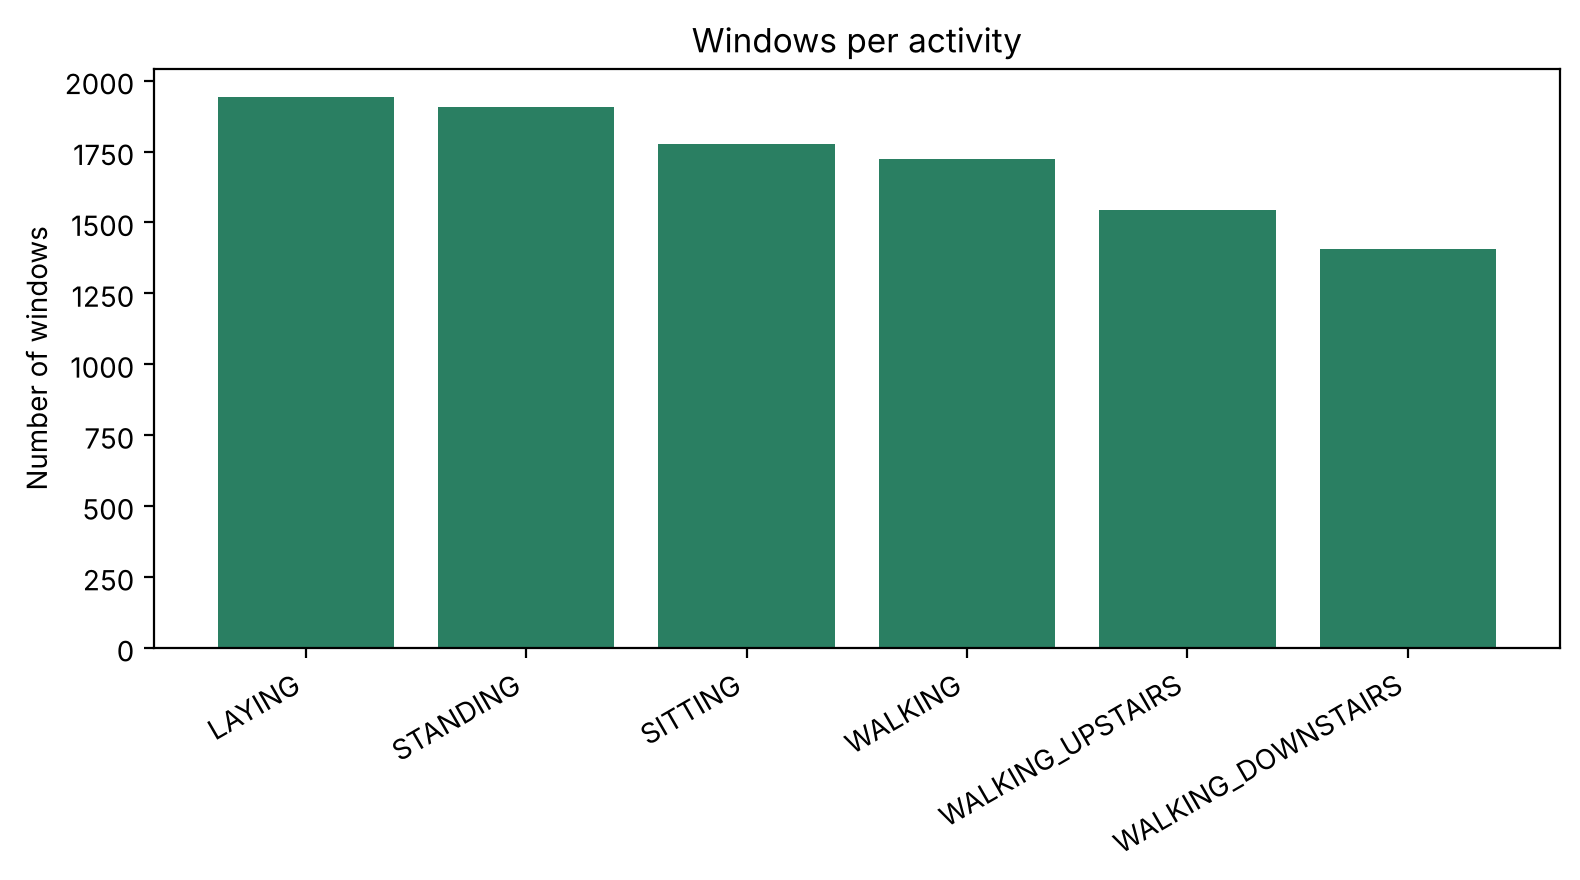

In [3]:
from edgefit.evaluation import plot_class_distribution

plot_class_distribution(freq)
plt.show()

The dataset has 10,299 windows across six activities. The classes are reasonably balanced (shares
between about 14 % and 19 %), and there are no missing values. The features are already scaled to [-1, 1].

## Windows per subject

Every person contributes several hundred windows, and every person performs every activity. That is the
key structural fact for the rest of the project: windows from the same person are **not independent**.

In [4]:
per_subject = pd.crosstab(groups, activity)
print(f"Windows per subject: min {per_subject.sum(axis=1).min()}, max {per_subject.sum(axis=1).max()}")
per_subject.head(8)

Windows per subject: min 281, max 409


activity,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
subject,,,,,,
1,50,47,53,95,49,53
2,48,46,54,59,47,48
3,62,52,61,58,49,59
4,54,50,56,60,45,52
5,52,44,56,56,47,47
6,57,55,57,57,48,51
7,52,48,53,57,47,51
8,54,46,54,48,38,41


## Why the split has to be by person

Each subject contributes hundreds of windows with person-specific patterns such as gait, body size and phone
placement. If the same person appears in both training and test data, a model can partly recognise the
*person* rather than the *activity*, which inflates the score. The product must work for new users, so only a
split by subject measures the generalisation that matters.

The project therefore uses:

- **Final holdout:** subjects 25–30 (2,286 windows), untouched until the final evaluation.
- **Model development:** subjects 1–24, with 4-fold `StratifiedGroupKFold` so every subject stays in a
  single fold for cross-validation and tuning.

In [5]:
import json
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
FIG = REPORTS / "figures"
results = json.loads((REPORTS / "results.json").read_text())
pd.set_option("display.precision", 4)

In [6]:
print(f"Train: {results['train_rows']} windows | Test: {results['test_rows']} windows "
      f"(subjects {results['test_subjects']})")
pd.read_csv(REPORTS / "cv_folds.csv")

Train: 8013 windows | Test: 2286 windows (subjects [25, 26, 27, 28, 29, 30])


,fold,train_rows,val_rows,val_subjects
0,0,5963,2050,"[2, 7, 14, 15, 21, 24]"
1,1,6106,1907,"[5, 8, 10, 11, 19, 20]"
2,2,5965,2048,"[1, 4, 6, 13, 17, 18]"
3,3,6005,2008,"[3, 9, 12, 16, 22, 23]"


No validation subject appears in its training fold (`describe_folds` raises an error otherwise).
Next: [02 · Model comparison](02_model_comparison.ipynb).